In [9]:
import signalTreatment as st
import splitSignal as ss
import dataSorting as ds
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import os
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from prettytable import PrettyTable

In [3]:
class ConfusionMatrix(object):

    def __init__(self, labels: list):
        self.labels = labels
        self.num_classes = len(labels)
        self.matrix = np.zeros((self.num_classes, self.num_classes))

        self.metrics = {c: {'Precision': None, 'Recall': None,
                            'Specificity': None, 'F1_score': None} for c in labels}

    def update(self, preds, labels):
        for p, t in zip(preds, labels):
            self.matrix[p, t] += 1

    def summary(self):
        # calculate accuracy
        sum_TP = 0
        n = np.sum(self.matrix)
        for i in range(self.num_classes):
            sum_TP += self.matrix[i, i]
        acc = sum_TP / n
        print("the model accuracy is ", acc)

        # kappa
        sum_po = 0
        sum_pe = 0
        for i in range(len(self.matrix[0])):
            sum_po += self.matrix[i][i]
            row = np.sum(self.matrix[i, :])
            col = np.sum(self.matrix[:, i])
            sum_pe += row * col
        po = sum_po / n
        pe = sum_pe / (n * n)
        # print(po, pe)
        kappa = round((po - pe) / (1 - pe), 3)
        # print("the model kappa is ", kappa)

        # precision, recall, specificity
        table = PrettyTable()
        table.field_names = ["", "Precision",
                             "Recall", "Specificity", "F1score"]
        for i in range(self.num_classes):
            TP = self.matrix[i, i]
            FP = np.sum(self.matrix[i, :]) - TP
            FN = np.sum(self.matrix[:, i]) - TP
            TN = np.sum(self.matrix) - TP - FP - FN

            prec = round(TP / (TP + FP), 3) if TP + FP != 0 else 0.
#             print(prec)
            self.metrics[self.labels[i]]['Precision'] = prec
            rec = round(TP / (TP + FN), 3) if TP + FN != 0 else 0.
#             print(rec)
            self.metrics[self.labels[i]]['Recall'] = rec
            self.metrics[self.labels[i]]['Specificity'] = round(
                TN / (TN + FP), 3) if TN + FP != 0 else 0.
            self.metrics[self.labels[i]]['F1score'] = round(2*prec*rec /
                                                            (prec+rec)) if prec + rec != 0 else 0

            table.add_row([self.labels[i], self.metrics[self.labels[i]]['Precision'],
                          self.metrics[self.labels[i]]['Recall'], self.metrics[self.labels[i]]['Specificity'], self.metrics[self.labels[i]]['F1score']])

        print(table)
        return str(acc)

    def plot(self):
        matrix = self.matrix
        print(matrix)
        plt.imshow(matrix, cmap=plt.cm.Blues)

        plt.xticks(range(self.num_classes), self.labels, rotation=45)
        plt.yticks(range(self.num_classes), self.labels)
        plt.colorbar()
        plt.xlabel('True Labels')
        plt.ylabel('Predicted Labels')
        plt.title('Confusion matrix (acc='+self.summary()+')')

        thresh = matrix.max() / 2
        for x in range(self.num_classes):
            for y in range(self.num_classes):

                info = int(matrix[y, x])
                plt.text(x, y, info,
                         verticalalignment='center',
                         horizontalalignment='center',
                         color="white" if info > thresh else "black")
        plt.tight_layout()
        plt.show()

    def log(self, input_par, evaluation_par, classifier_par=None):
        """
        input :
        - input_par : dict of keys (window_length, window_shift, avg_window)
        - classifier_par : dict of keys (name, params)
        - evaluation_par : dict of keys (train_config, train_subjects, test_config, test_subjects)
        """
        # Evaluation and training configuration
        train_config = evaluation_par['train_config']
        train_subject = evaluation_par['train_subject']
        test_config = evaluation_par['test_config']
        test_subject = evaluation_par['test_subject']
        if len(train_subject) == 5 & len(test_subject) == 5:
            evaluation_paradigm = 'common_subject'
        elif len(test_subject) == 1:
            if len(train_subject) == 4 and test_subject[0] not in train_subject:
                evaluation_paradigm = 'leave_one_out'
            elif len(train_subject) == 1 and train_subject[0] == test_subject[0]:
                evaluation_paradigm = 'subject_specific'
            else:
                evaluation_paradigm = 'unknown'
        else:
            evaluation_paradigm = 'unknown'

        # Stft parameters
        window_size = input_par['window_size']
        window_shift = input_par['window_shift']
        avg_window = input_par['avg_filter_size']

        # Classifier parameters
        classifier_name = classifier_par['name']
        classifier_par = classifier_par['model_params']

        # calculate accuracy
        sum_TP = 0
        n = np.sum(self.matrix)
        for i in range(self.num_classes):
            sum_TP += self.matrix[i, i]
        acc = sum_TP / n
#         print("the model accuracy is ", acc)

        # kappa
        sum_po = 0
        sum_pe = 0
        for i in range(len(self.matrix[0])):
            sum_po += self.matrix[i][i]
            row = np.sum(self.matrix[i, :])
            col = np.sum(self.matrix[:, i])
            sum_pe += row * col
        po = sum_po / n
        pe = sum_pe / (n * n)
        # print(po, pe)
        kappa = round((po - pe) / (1 - pe), 3)
        # print("the model kappa is ", kappa)

        # precision, recall, specificity
        table = PrettyTable()
        table.field_names = ["", "Precision",
                             "Recall", "Specificity", "F1score"]
        for i in range(self.num_classes):
            TP = self.matrix[i, i]
            FP = np.sum(self.matrix[i, :]) - TP
            FN = np.sum(self.matrix[:, i]) - TP
            TN = np.sum(self.matrix) - TP - FP - FN

            prec = round(TP / (TP + FP), 3) if TP + FP != 0 else 0.
#             print(prec)
            self.metrics[self.labels[i]]['Precision'] = prec
            rec = round(TP / (TP + FN), 3) if TP + FN != 0 else 0.
#             print(rec)
            self.metrics[self.labels[i]]['Recall'] = rec
            self.metrics[self.labels[i]]['Specificity'] = round(
                TN / (TN + FP), 3) if TN + FP != 0 else 0.
            self.metrics[self.labels[i]]['F1score'] = round(2*prec*rec /
                                                            (prec+rec)) if prec + rec != 0 else 0

            table.add_row([self.labels[i], self.metrics[self.labels[i]]['Precision'],
                          self.metrics[self.labels[i]]['Recall'], self.metrics[self.labels[i]]['Specificity'], self.metrics[self.labels[i]]['F1score']])
        # Metrics (recall, precision) for each class, then balanced accuracy
        recall_f = self.metrics['focused']['Recall']
        precision_f = self.metrics['focused']['Precision']
        recall_u = self.metrics['unfocused']['Recall']
        precision_u = self.metrics['unfocused']['Precision']
        recall_d = self.metrics['drowsed']['Recall']
        precision_d = self.metrics['drowsed']['Precision']
        bal_acc = (recall_f + recall_u + recall_d)/3

        score_list = [train_config, train_subject, test_config, test_subject, evaluation_paradigm,
                      window_size, window_shift, avg_window,
                      classifier_name, classifier_par,
                      bal_acc, recall_f, precision_f, recall_u, precision_u, recall_d, precision_d]
        # score_list must have
#         if os.path.exists(os.path.join(CURRENT_FOLDER_NAME, CSV_SCORE_FILE_NAME)):
        with open(os.path.join(CURRENT_FOLDER_NAME, CSV_SCORE_FILE_NAME), 'a') as f_object:
            # Pass this file object to csv.writer()
            # and get a writer object
            writer_object = writer(f_object)

            # Pass the list as an argument into
            # the writerow()
            writer_object.writerow(score_list)

            # Close the file object
            f_object.close()

In [10]:
# Exemple de données
X = np.random.rand(100, 36, 64)  # 100 échantillons avec des dimensions (36, 64)
y = np.random.randint(0, 2, size=(100, 3))
print(y[0])  # 100 échantillons avec des labels one-hot encodés


# Aplatir les dimensions (36, 64) en une seule dimension (36*64)
X_flat = X.reshape(X.shape[0], -1)

# Convertir les étiquettes one-hot en étiquettes de classe
y_labels = np.argmax(y, axis=1) 

from sklearn.model_selection import train_test_split

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X_flat, y_labels, test_size=0.3, random_state=42)

# Initialiser le classifieur
clf = RandomForestClassifier(n_estimators=100, random_state=42)

# Entraîner le modèle
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)


# Évaluer le modèle
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Afficher un rapport de classification
print('Classification Report:')
print(classification_report(y_test, y_pred))

[0 1 0]
Accuracy: 0.70
Classification Report:
              precision    recall  f1-score   support

           0       0.70      1.00      0.82        21
           1       0.00      0.00      0.00         6
           2       0.00      0.00      0.00         3

    accuracy                           0.70        30
   macro avg       0.23      0.33      0.27        30
weighted avg       0.49      0.70      0.58        30



c:\Users\quent\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\quent\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\quent\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

[[21.  6.  3.]
 [ 0.  0.  0.]
 [ 0.  0.  0.]]
the model accuracy is  0.7
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |    0.7    |  1.0   |     0.0     |    1    |
| 1 |    0.0    |  0.0   |     1.0     |    0    |
| 2 |    0.0    |  0.0   |     1.0     |    0    |
+---+-----------+--------+-------------+---------+


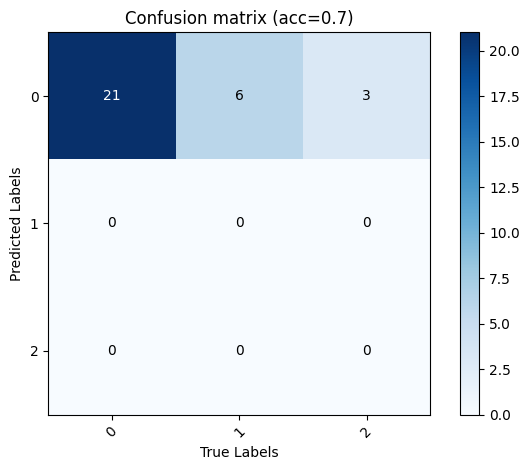

In [11]:
import matplotlib.pyplot as plt
confusion_1 = ConfusionMatrix(labels=['0','1','2'])
confusion_1.update(clf.predict(X_test), y_test)
confusion_1.plot()